In [52]:
import pandas as pd

data = pd.read_csv("eruption.txt", sep=r"\s+", names=["index", "col1", "col2"])

X = data[["col1", "col2"]].values

print(f"Dataset shape: {X.shape}")
print(X[:5])

Dataset shape: (272, 2)
[[ 3.6   79.   ]
 [ 1.8   54.   ]
 [ 3.333 74.   ]
 [ 2.283 62.   ]
 [ 4.533 85.   ]]


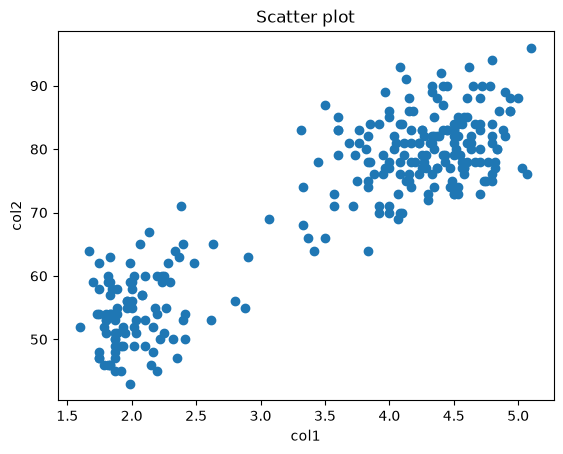

In [53]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1])
plt.title("Scatter plot")
plt.xlabel("col1")
plt.ylabel("col2")
plt.show()

In [54]:
from scipy.stats import multivariate_normal
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import time

K = 2
max_iter = 100
tol = 1e-4
n_samples, n_features = X.shape

results = {}

for strategy in ["random", "kmeans"]:
    np.random.seed(15)
    start_time = time.time()
    
    if strategy == "random":
        random_indexes = np.random.choice(n_samples, K, replace=False)
        means = X[random_indexes].astype(float)
        weights = np.ones(K) / K
        overall_variance = np.var(X, axis=0)
        covariances = np.array([np.diag(overall_variance) for _ in range(K)])

    elif strategy == "kmeans":
        kmeans = KMeans(n_clusters=K, random_state= 15, n_init=10)
        kmeans_labels = kmeans.fit_predict(X)

        means = kmeans.cluster_centers_.astype(float)
        weights = np.zeros(K)
        covariances = np.zeros((K, n_features, n_features))

        for k in range(K):
            cluster_data = X[kmeans_labels == k]
            weights[k] = len(cluster_data) / n_samples
            # Add small epsilon to diagonal to prevent singular matrices
            covariances[k] = np.cov(cluster_data.T) + np.eye(n_features) * 1e-6

    # EM ALGORITHM LOOP
    log_likelihoods = []
    for iteration in range(max_iter):
        
        # E step
        responsibilities = np.zeros((n_samples, K))
        for k in range(K):
            pdf = multivariate_normal.pdf(X, mean=means[k], cov=covariances[k])
            responsibilities[:, k] = weights[k] * pdf

        sum_responsibilities = responsibilities.sum(axis=1)[:, np.newaxis]
        responsibilities = responsibilities / sum_responsibilities

        # M step
        N_k = responsibilities.sum(axis=0)
        for k in range(K):
            means[k] = (1 / N_k[k]) * np.sum(responsibilities[:, k, np.newaxis] * X, axis=0)
            diff = X - means[k]
            weighted_diff = responsibilities[:, k, np.newaxis] * diff
            covariances[k] = (1 / N_k[k]) * np.dot(weighted_diff.T, diff) + np.eye(n_features) * 1e-6

            weights[k] = N_k[k] / n_samples

        current_ll = 0
        for k in range(K):
            pdf = multivariate_normal.pdf(X, mean=means[k], cov=covariances[k])
            current_ll += weights[k] * pdf

        current_ll = np.sum(np.log(current_ll))
        log_likelihoods.append(current_ll)

        if iteration > 0 and np.abs(current_ll - log_likelihoods[-2]) < tol:
            break

    exec_time = time.time() - start_time
    final_cluster_assignments = np.argmax(responsibilities, axis=1)
    silhouette = silhouette_score(X, final_cluster_assignments)

    print(f"Iteration: {iteration + 1}")
    print(f"Execution time: {exec_time:.5f} seconds")
    print(f"Final log likelihood: {log_likelihoods[-1]:.5f}")
    print(f"Silhouette score: {silhouette:.5f}\n")

    results[strategy] = {
        "labels": final_cluster_assignments,
        "log_likelihoods": log_likelihoods,
        "means": np.copy(means),
        "covariances": np.copy(covariances)
    }

Iteration: 24
Execution time: 0.00679 seconds
Final log likelihood: -1130.26396
Silhouette score: 0.70963

Iteration: 6
Execution time: 0.00755 seconds
Final log likelihood: -1130.26396
Silhouette score: 0.70963



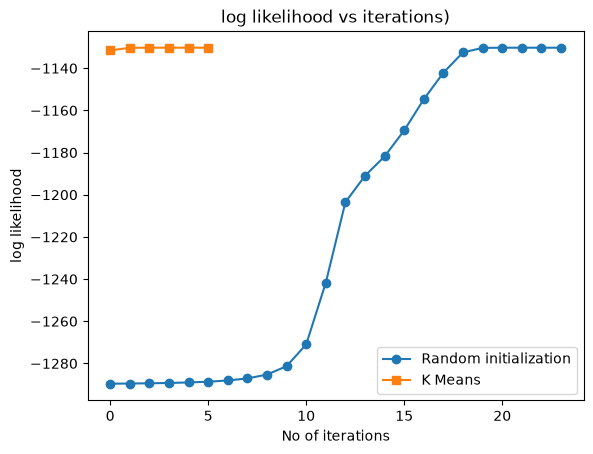

In [55]:
import matplotlib.pyplot as plt

plt.plot(results["random"]["log_likelihoods"], marker="o", label="Random initialization")
plt.plot(results["kmeans"]["log_likelihoods"], marker="s", label="K Means")
plt.title("log likelihood vs iterations)")
plt.xlabel("No of iterations")
plt.ylabel("log likelihood")
plt.legend()
plt.show()

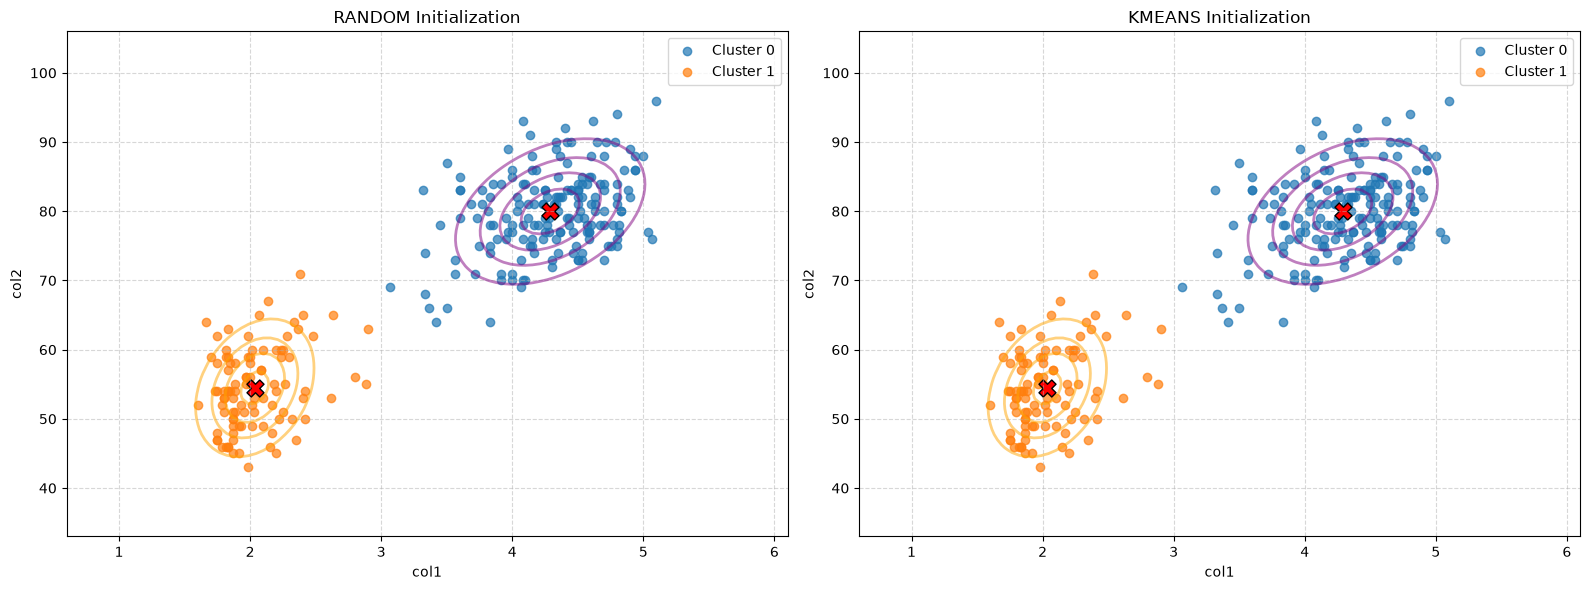

In [56]:
# Contour plot

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 10, X[:, 1].max() + 10

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
strategies = ['random', 'kmeans']
colors = ['purple', 'orange']

for idx, strategy in enumerate(strategies):
    ax = axes[idx]
    labels = results[strategy]['labels']
    means = results[strategy]['means']
    covariances = results[strategy]['covariances']
    
    # Plot data points colored by cluster
    for k in range(K):
        cluster_points = X[labels == k]
        ax.scatter(cluster_points[:, 0], cluster_points[:, 1], alpha=0.7, label=f'Cluster {k}')
        
        # Plot Gaussian Covariance Contours (Ellipses)
        rv = multivariate_normal(means[k], covariances[k])
        zz = rv.pdf(grid).reshape(xx.shape)
        ax.contour(xx, yy, zz, levels=4, colors=colors[k], alpha=0.5, linewidths=2)
        ax.scatter(means[k, 0], means[k, 1], marker='X', s=150, color='red', edgecolor='k')

    ax.set_title(f"{strategy.upper()} Initialization")
    ax.set_xlabel('col1')
    ax.set_ylabel('col2')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()